In [ ]:
import numpy as np
import pandas as pd

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df=pd.read_csv('/content/computer_prices_all.csv')

In [ ]:
df=df[df['device_type']=="Laptop"]

In [ ]:
df.head()


,ID,device_type,brand,model,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,...,resolution,refresh_hz,battery_wh,charger_watts,psu_watts,wifi,bluetooth,weight_kg,warranty_months,price
1,1,Laptop,Samsung,Samsung Pro KM8,2022,Windows,Mainstream,Intel,Intel i7-11114,4,...,1920x1080,90.0,56.0,120.0,0.0,Wi-Fi 6,5.3,2.03,12.0,2274.99
4,4,Laptop,Gigabyte,Gigabyte Pro IX1,2024,Linux,Gaming,AMD,AMD Ryzen 7 6230,5,...,2560x1600,90.0,80.0,90.0,0.0,Wi-Fi 6,5.2,1.50,12.0,2681.99
8,8,Laptop,Dell,Dell Creator GIQ,2024,Windows,Mainstream,Intel,Intel i9-14473,6,...,2560x1600,60.0,80.0,240.0,0.0,Wi-Fi 5,5.0,1.17,48.0,2953.99
9,9,Laptop,Lenovo,Lenovo Blade MIZ,2025,Windows,Ultrabook,AMD,AMD Ryzen 3 4374,1,...,3840x2160,120.0,60.0,45.0,0.0,Wi-Fi 6,5.3,1.50,24.0,1653.99
10,10,Laptop,HP,HP Pro 6XS,2023,Windows,Mainstream,Intel,Intel i5-13209,2,...,1920x1080,165.0,70.0,90.0,0.0,Wi-Fi 6E,5.2,1.24,36.0,1371.99


In [ ]:
df['cpu_family'] = df['cpu_model'].apply(
    lambda x: 'Intel i7' if 'Intel i7' in x
    else 'Intel i3' if 'Intel i3' in x
    else 'Intel i5' if 'Intel i5' in x
    else 'Intel i9' if 'Intel i9' in x



    else 'AMD Ryzen 5' if 'AMD Ryzen 5' in x
    else 'AMD Ryzen 7' if 'AMD Ryzen 7' in x
    else 'AMD Ryzen 3' if 'AMD Ryzen 3' in x
    else 'AMD Ryzen 9' if 'AMD Ryzen 9' in x
    else 'Apple M1' if 'M1' in x
    else 'Apple M2' if 'M2' in x
    else 'Apple M3' if 'M3' in x
    else 'Apple M4' if 'M4' in x
    else 'others'
)

In [ ]:
df[df['cpu_family'] == 'others']['cpu_model'].value_counts()

,count
cpu_model,


In [ ]:
df.sample(15)

,ID,device_type,brand,model,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,...,refresh_hz,battery_wh,charger_watts,psu_watts,wifi,bluetooth,weight_kg,warranty_months,price,cpu_family
20022,20022,Laptop,HP,HP Blade U2Q,2020,Windows,Gaming,Intel,Intel i5-13766,2,...,60.0,90.0,120.0,0.0,Wi-Fi 6,5.1,2.37,24.0,1760.99,Intel i5
22925,22925,Laptop,HP,HP Blade MUU,2022,Windows,Gaming,AMD,AMD Ryzen 3 6234,1,...,60.0,70.0,120.0,0.0,Wi-Fi 6,5.2,1.50,12.0,1115.99,AMD Ryzen 3
37200,37200,Laptop,ASUS,ASUS Nitro UKZ,2023,macOS,Gaming,Intel,Intel i5-12159,3,...,60.0,56.0,180.0,0.0,Wi-Fi 7,5.3,1.64,24.0,2263.99,Intel i5
80271,80271,Laptop,ASUS,ASUS Pro XWE,2025,macOS,Ultrabook,Intel,Intel i3-10736,1,...,60.0,80.0,65.0,0.0,Wi-Fi 6,5.0,1.13,12.0,1589.99,Intel i3
47000,47000,Laptop,Gigabyte,Gigabyte Creator RS1,2025,Windows,Gaming,Intel,Intel i7-14716,4,...,120.0,70.0,180.0,0.0,Wi-Fi 5,4.2,2.00,24.0,2573.99,Intel i7
8585,8585,Laptop,HP,HP Legion 9XC,2018,Linux,Gaming,Intel,Intel i7-13591,4,...,120.0,50.0,45.0,0.0,Wi-Fi 7,5.1,1.70,36.0,2450.99,Intel i7
6603,6603,Laptop,Lenovo,Lenovo Nitro HEA,2021,Windows,Gaming,Intel,Intel i5-12445,2,...,90.0,80.0,65.0,0.0,Wi-Fi 6,5.2,1.10,12.0,1271.99,Intel i5
74209,74209,Laptop,ASUS,ASUS Air DLW,2023,Windows,Ultrabook,Intel,Intel i7-14205,4,...,60.0,80.0,120.0,0.0,Wi-Fi 5,5.2,1.37,12.0,2563.99,Intel i7
54383,54383,Laptop,Apple,Apple Pro ZPG,2023,Windows,Mainstream,Apple,Apple M3 Max,2,...,120.0,90.0,90.0,0.0,Wi-Fi 6,5.0,1.50,12.0,2181.99,Apple M3
2098,2098,Laptop,Dell,Dell Air 6WV,2024,Windows,Mainstream,AMD,AMD Ryzen 5 3883,2,...,120.0,50.0,120.0,0.0,Wi-Fi 6,5.3,1.30,36.0,2165.99,AMD Ryzen 5


In [ ]:
df=df.drop(columns=['ID','device_type','psu_watts'])

In [ ]:
df=df.drop(columns=['model'])

In [ ]:
df.shape

(54404, 31)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 54404 entries, 1 to 90944
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                54404 non-null  object 
 1   release_year         54404 non-null  int64  
 2   os                   54404 non-null  object 
 3   form_factor          54404 non-null  object 
 4   cpu_brand            54404 non-null  object 
 5   cpu_model            54404 non-null  object 
 6   cpu_tier             54404 non-null  int64  
 7   cpu_cores            54404 non-null  int64  
 8   cpu_threads          54404 non-null  int64  
 9   cpu_base_ghz         54404 non-null  float64
 10                       54404 non-null  float64
 11  gpu_brand            54404 non-null  object 
 12  gpu_model            54404 non-null  object 
 13  gpu_tier             54404 non-null  float64
 14  vram_gb              54404 non-null  float64
 15  ram_gb               54404 non-null  floa

In [ ]:
df=df.dropna()

/tmp/ipykernel_477/49132842.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((df['price']))


<Axes: xlabel='price', ylabel='Density'>

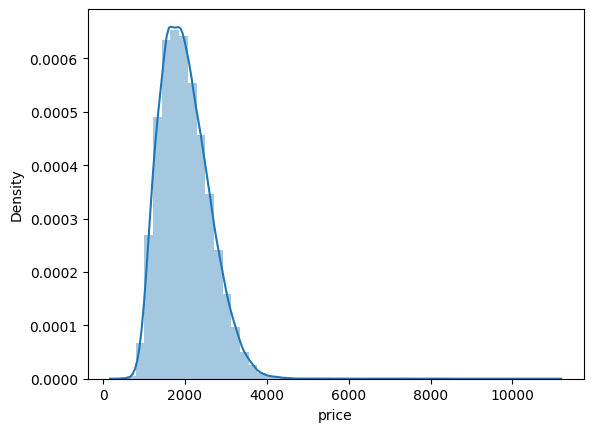

In [ ]:
sns.distplot((df['price']))

/tmp/ipykernel_477/2721140454.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(np.log(df['price']))


<Axes: xlabel='price', ylabel='Density'>

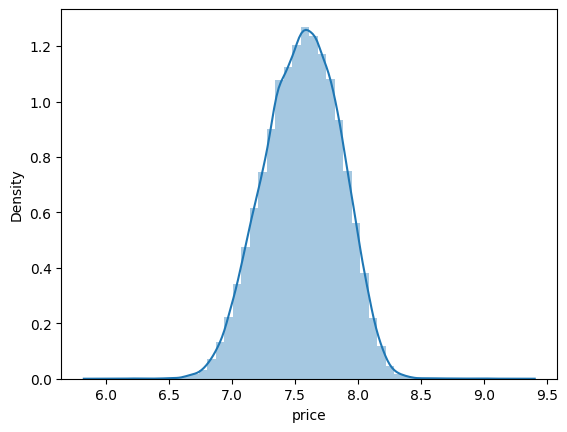

In [ ]:
sns.distplot(np.log(df['price']))

In [ ]:
np.log(df['price']).skew()

np.float64(-0.12130426789010156)

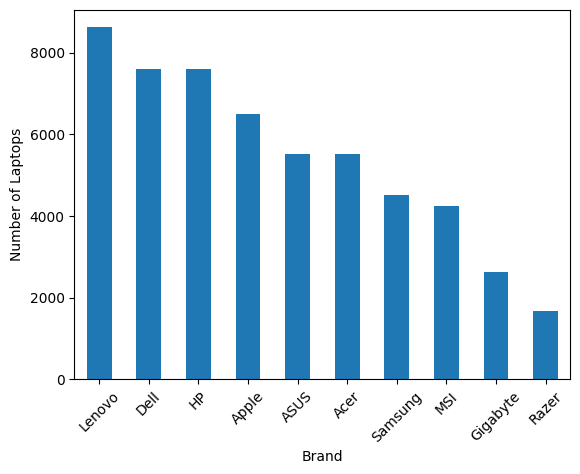

In [ ]:
df['brand'].value_counts().plot(kind='bar')
plt.xlabel('Brand')
plt.ylabel('Number of Laptops')
plt.xticks(rotation=45)
plt.show()

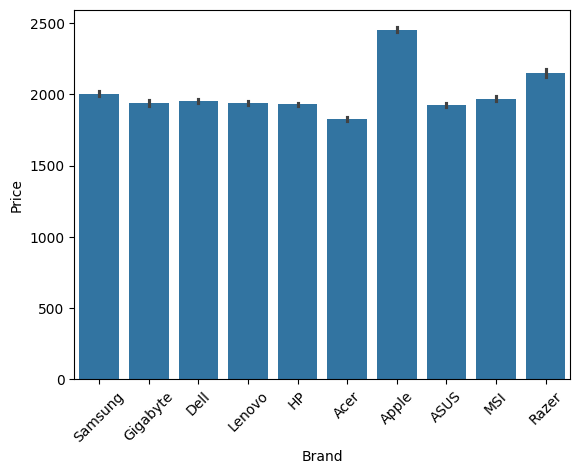

In [ ]:
sns.barplot(x=df['brand'],y=df['price'])
plt.xlabel('Brand')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='release_year'>

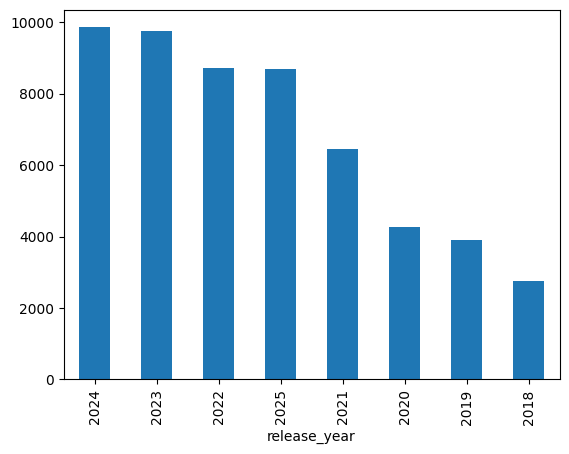

In [ ]:
df['release_year'].value_counts().plot(kind='bar')

<Axes: xlabel='release_year', ylabel='price'>

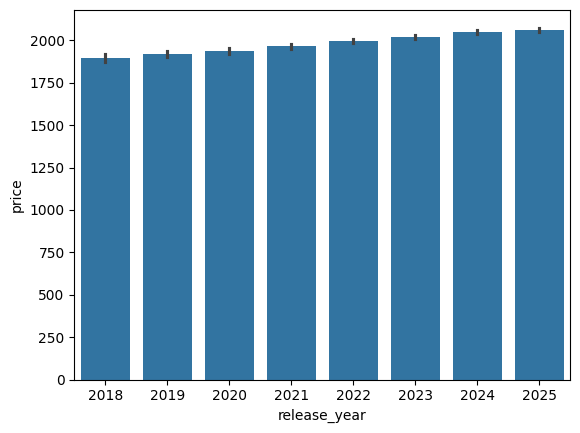

In [ ]:
sns.barplot(x=df['release_year'],y=df['price'])

<Axes: xlabel='os'>

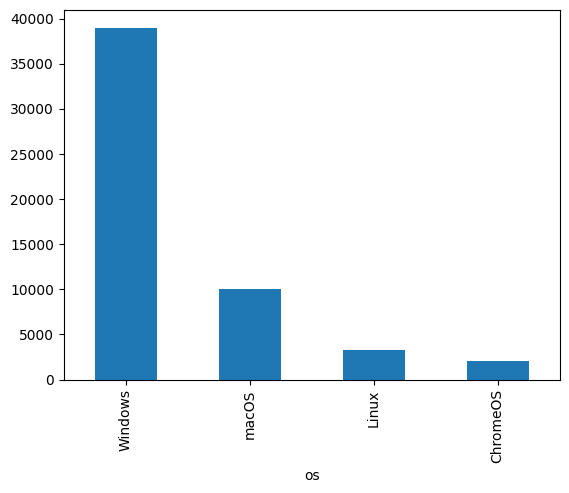

In [ ]:
df['os'].value_counts().plot(kind='bar')

<Axes: xlabel='os', ylabel='price'>

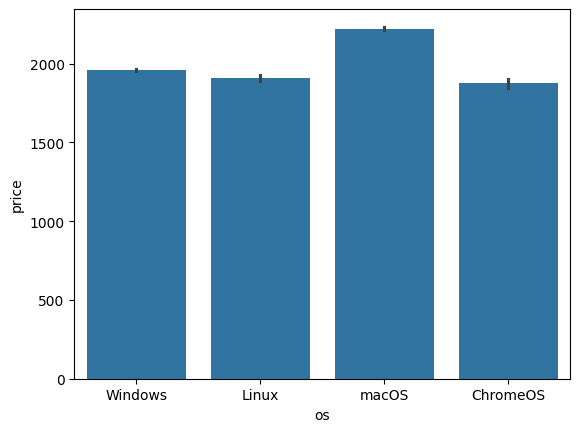

In [ ]:
sns.barplot(x=df['os'],y=df['price'])

<Axes: xlabel='form_factor'>

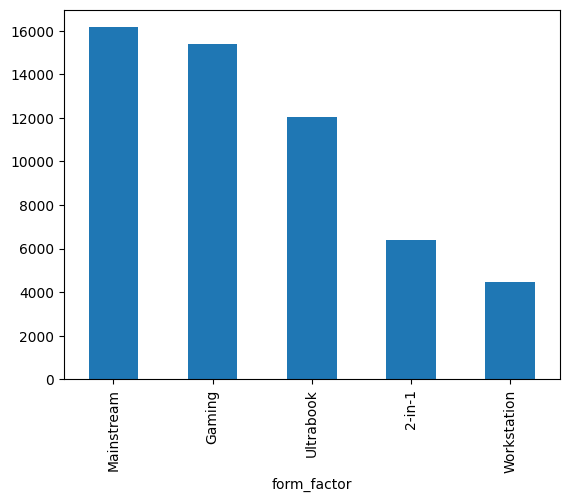

In [ ]:
df['form_factor'].value_counts().plot(kind='bar')

<Axes: xlabel='form_factor', ylabel='price'>

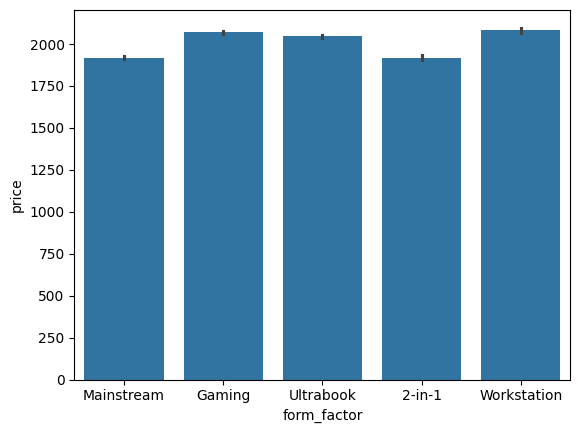

In [ ]:
sns.barplot(x=df['form_factor'],y=df['price'])

<Axes: xlabel='cpu_brand'>

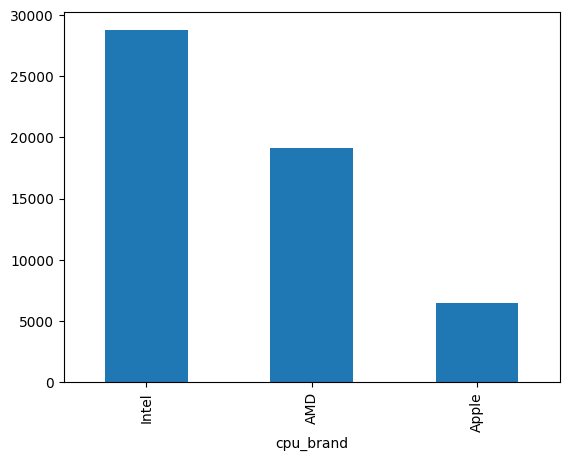

In [ ]:
df['cpu_brand'].value_counts().plot(kind='bar')

<Axes: xlabel='cpu_brand', ylabel='price'>

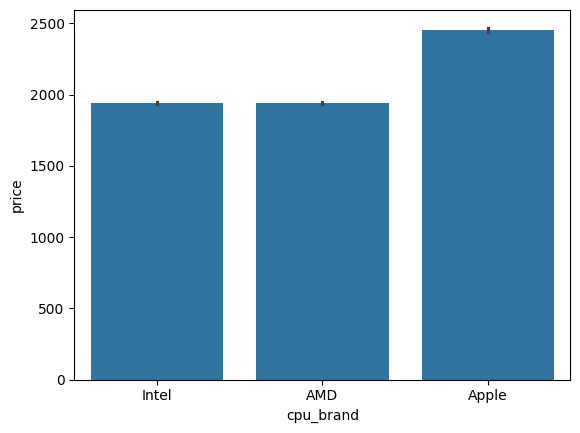

In [ ]:
sns.barplot(x=df['cpu_brand'],y=df['price'])

In [ ]:
df['cpu_model'].value_counts()

,count
cpu_model,
Apple M2 Pro,768
Apple M1 Pro,735
Apple M3 Pro,730
Apple M2 Max,728
Apple M1,726
...,...
AMD Ryzen 3 5701,1
Intel i7-13707,1
AMD Ryzen 9 3455,1


In [ ]:
y=df['cpu_model'].value_counts()

In [ ]:
y.sample(1000)

,count
cpu_model,
AMD Ryzen 5 6808,1
Intel i7-14470,4
Intel i5-10320,2
Intel i9-12353,2
Intel i5-13278,6
...,...
Intel i7-14302,1
Intel i9-11125,1
AMD Ryzen 5 5195,2


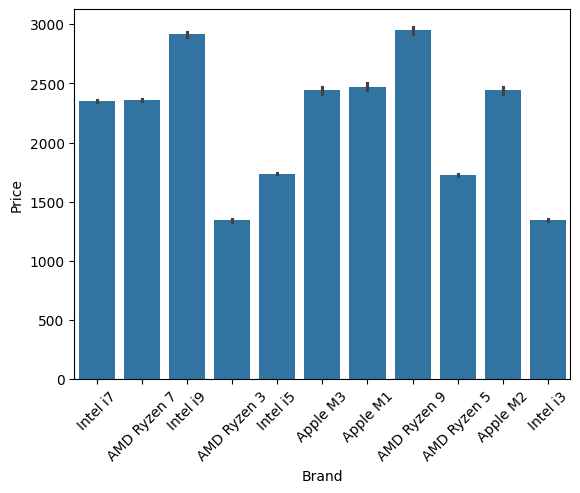

In [ ]:
sns.barplot(x=df['cpu_family'],y=df['price'])
plt.xlabel('Brand')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='cpu_family'>

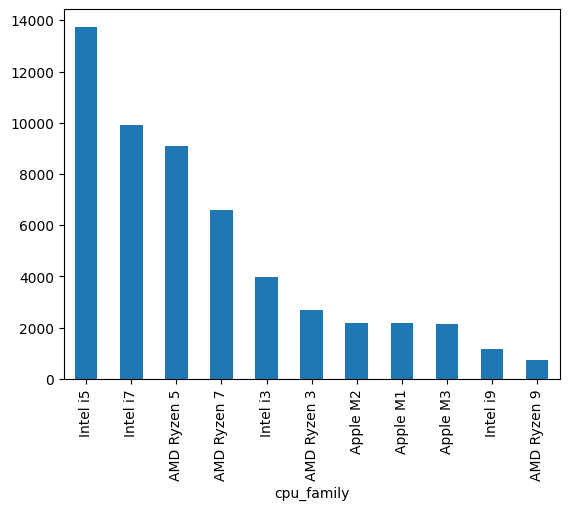

In [ ]:
df['cpu_family'].value_counts().plot(kind='bar')


<Axes: xlabel='cpu_tier'>

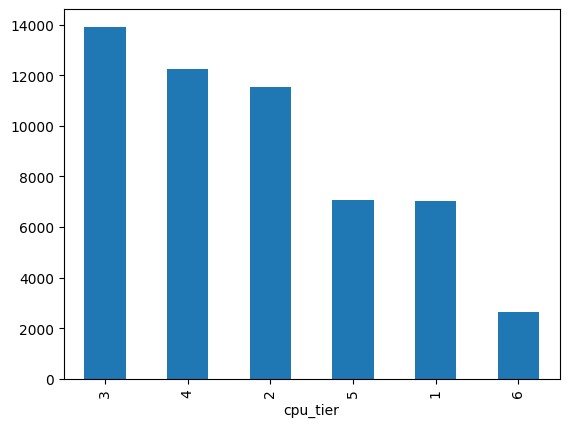

In [ ]:
df['cpu_tier'].value_counts().plot(kind='bar')

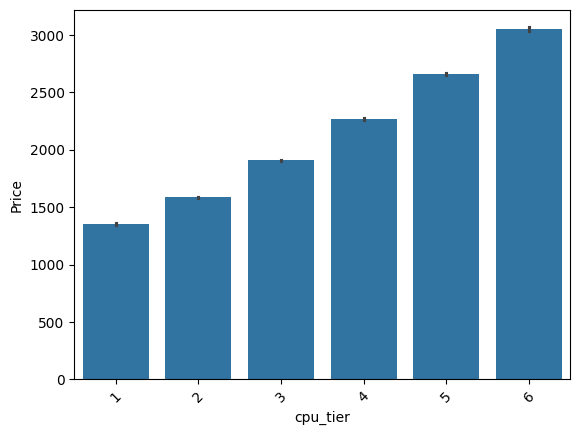

In [ ]:
sns.barplot(x=df['cpu_tier'],y=df['price'])
plt.xlabel('cpu_tier')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='cpu_cores'>

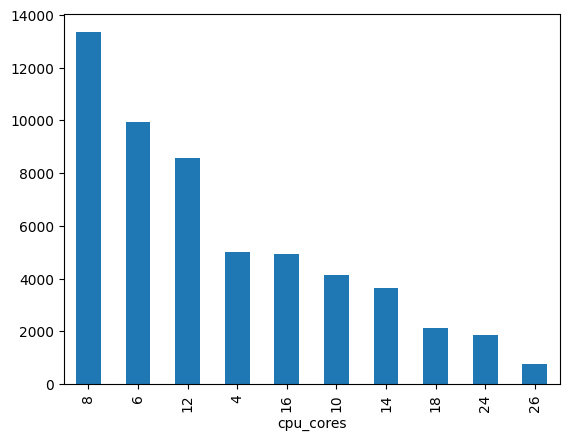

In [ ]:
df['cpu_cores'].value_counts().plot(kind='bar')

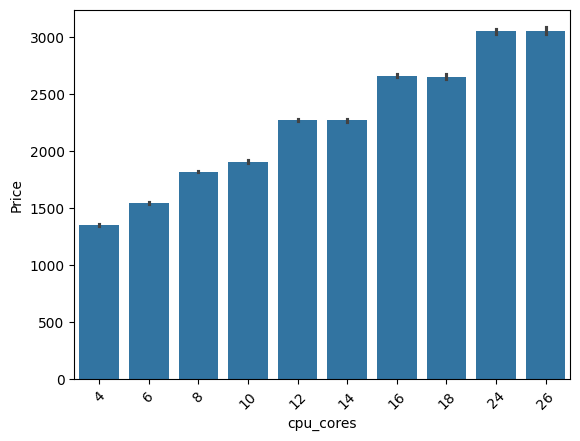

In [ ]:
sns.barplot(x=df['cpu_cores'],y=df['price'])
plt.xlabel('cpu_cores')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='cpu_threads'>

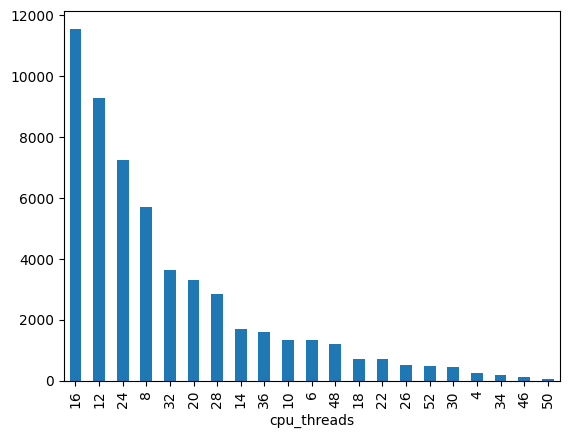

In [ ]:
df['cpu_threads'].value_counts().plot(kind='bar')

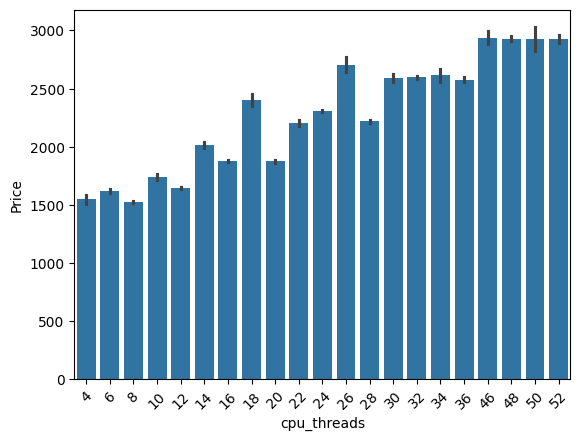

In [ ]:
sns.barplot(x=df['cpu_threads'],y=df['price'])
plt.xlabel('cpu_threads')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='cpu_base_ghz'>

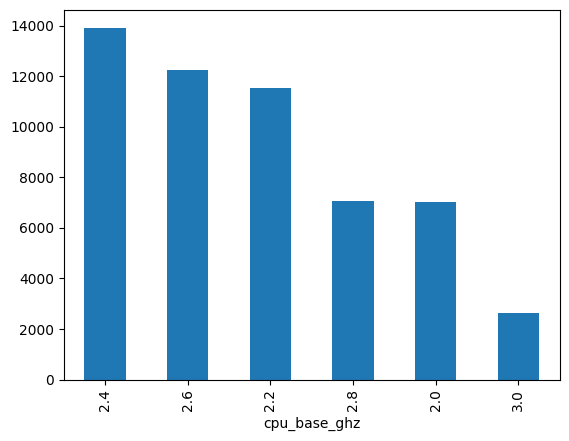

In [ ]:
df['cpu_base_ghz'].value_counts().plot(kind='bar')

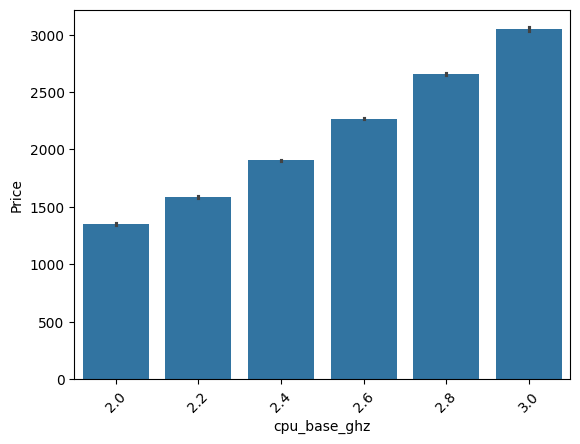

In [ ]:
sns.barplot(x=df['cpu_base_ghz'],y=df['price'])
plt.xlabel('cpu_base_ghz')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='gpu_brand'>

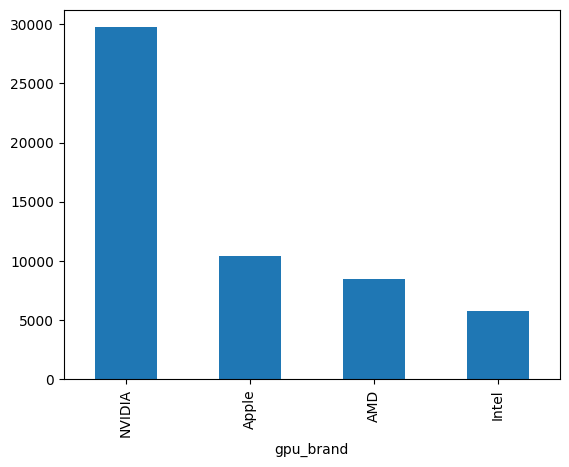

In [ ]:
df['gpu_brand'].value_counts().plot(kind='bar')

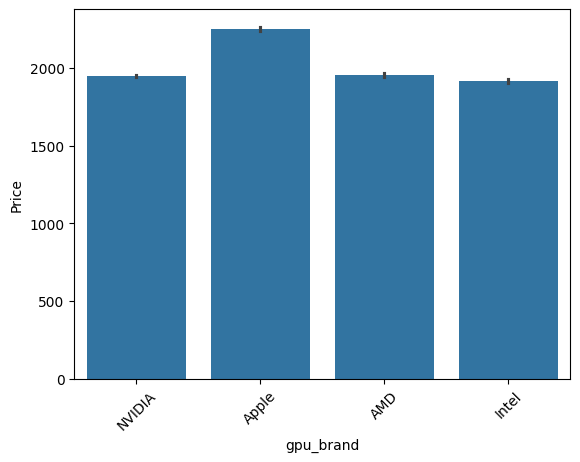

In [ ]:
sns.barplot(x=df['gpu_brand'],y=df['price'])
plt.xlabel('gpu_brand')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

In [ ]:
df.drop(columns=df.columns[10],inplace=True)

In [ ]:
df['gpu_model'].value_counts()

,count
gpu_model,
Apple Integrated,10386
RTX 40 50,3109
RTX 30 50,3080
RTX 30 70,3049
RTX 40 70,3025
RTX 40 60,2978
RTX 30 60,2925
RTX 40 80,2435
RTX 30 80,2368


In [ ]:
df['gpu_family']=df['gpu_model'].apply(
    lambda x: 'Intel Arc series' if 'Arc' in x
    else 'RTX 4080 series' if 'RTX 40 80' in x
    else 'RTX 3080 series' if 'RTX 30 80' in x
    else 'RTX 2080 series' if 'RTX 20 80' in x
    else 'RX 5000 series' if 'RX 5000' in x
    else 'RX 6000 series' if 'RX 6000' in x
    else 'RX 7000 series' if 'RX 7000' in x

    else x

)

In [ ]:
df['gpu_family'].value_counts()

,count
gpu_family,
Apple Integrated,10386
Intel Arc series,5768
RX 7000 series,3866
RX 6000 series,3785
RTX 4080 series,3768
RTX 3080 series,3766
RTX 40 50,3109
RTX 30 50,3080
RTX 30 70,3049


<Axes: xlabel='gpu_family'>

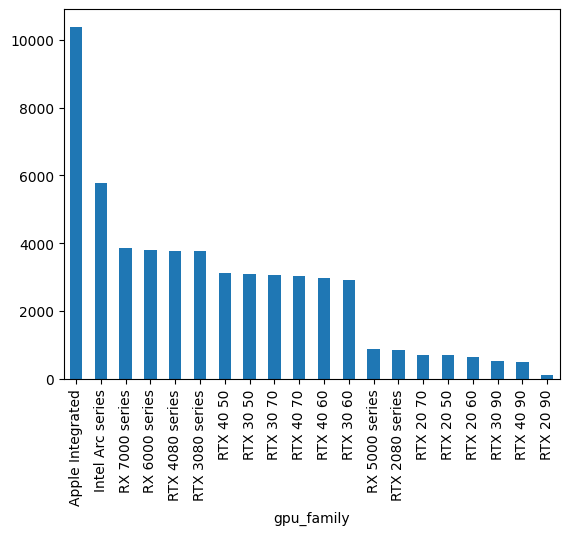

In [ ]:
df['gpu_family'].value_counts().plot(kind='bar')

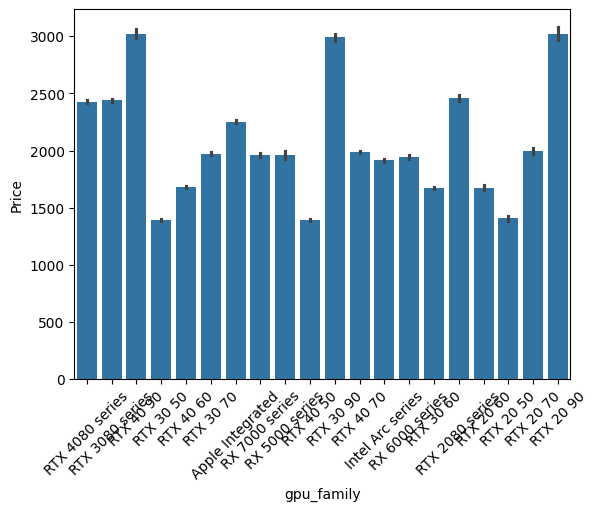

In [ ]:
sns.barplot(x=df['gpu_family'],y=df['price'])
plt.xlabel('gpu_family')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='gpu_tier'>

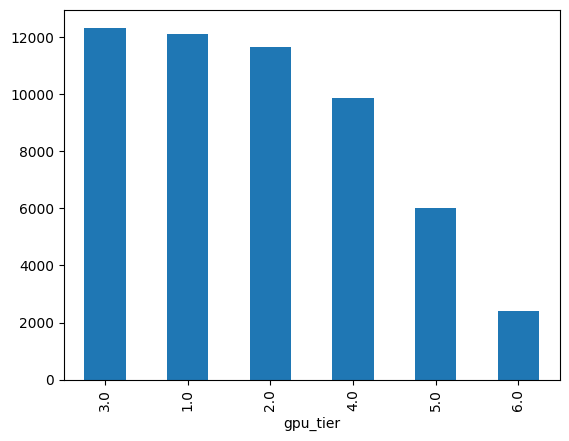

In [ ]:
df['gpu_tier'].value_counts().plot(kind='bar')

<Axes: xlabel='vram_gb'>

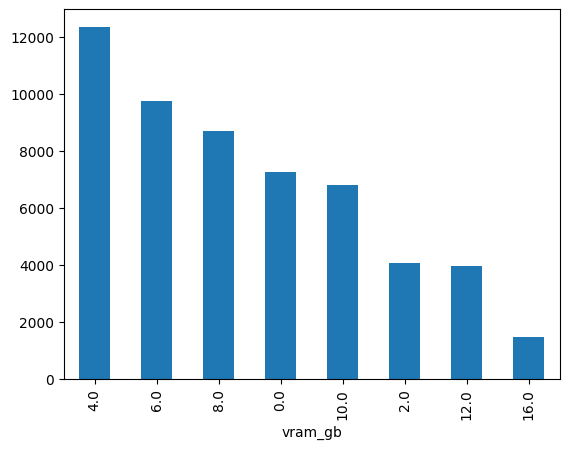

In [ ]:
df['vram_gb'].value_counts().plot(kind='bar')

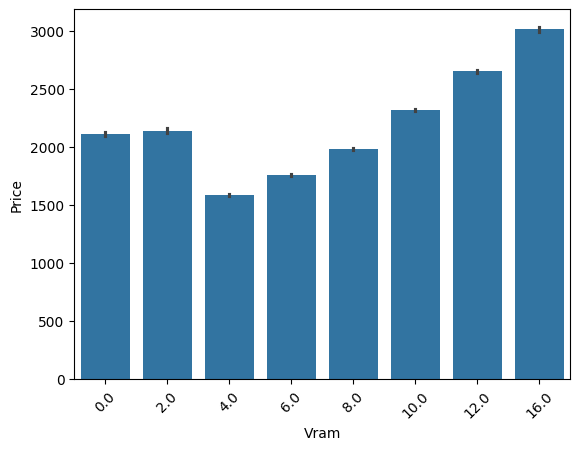

In [ ]:
sns.barplot(x=df['vram_gb'],y=df['price'])
plt.xlabel('Vram')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

In [ ]:
#same with ram

<Axes: xlabel='storage_type'>

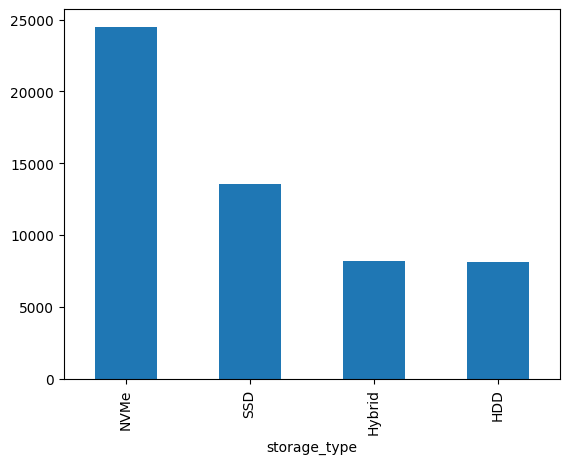

In [ ]:
df['storage_type'].value_counts().plot(kind='bar')

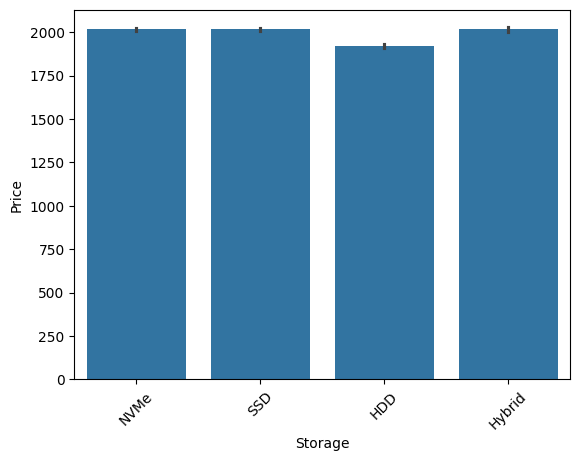

In [ ]:
sns.barplot(x=df['storage_type'],y=df['price'])
plt.xlabel('Storage')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='storage_gb'>

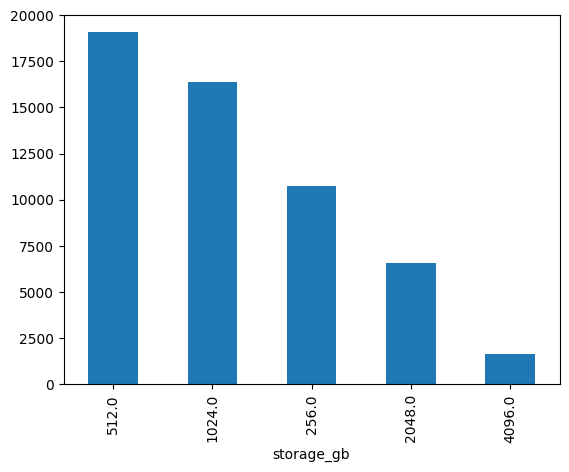

In [ ]:
df['storage_gb'].value_counts().plot(kind='bar')

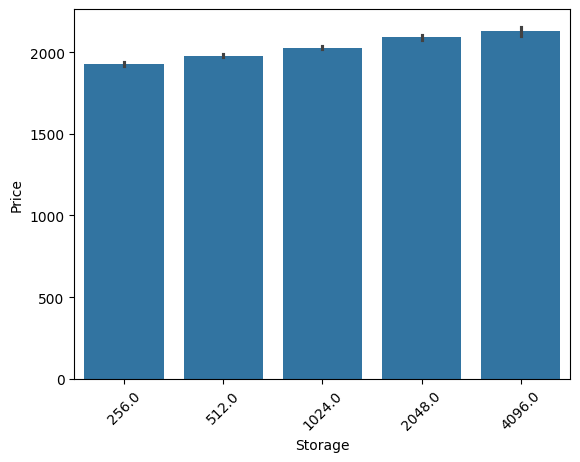

In [ ]:
sns.barplot(x=df['storage_gb'],y=df['price'])
plt.xlabel('Storage')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='display_type'>

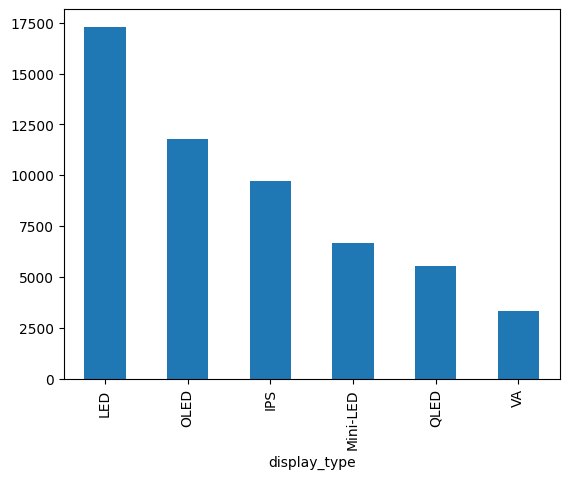

In [ ]:
df['display_type'].value_counts().plot(kind='bar')

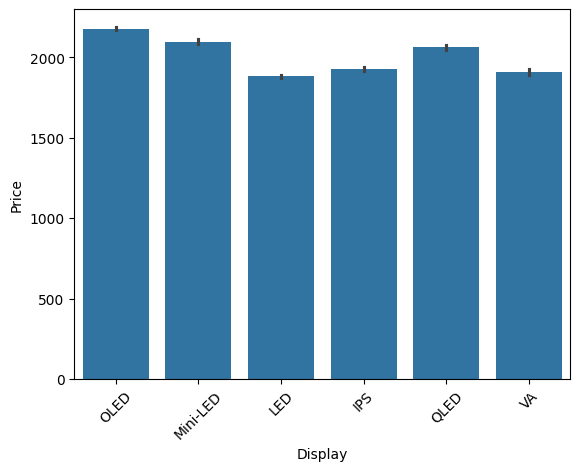

In [ ]:
sns.barplot(x=df['display_type'],y=df['price'])
plt.xlabel('Display')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='refresh_hz'>

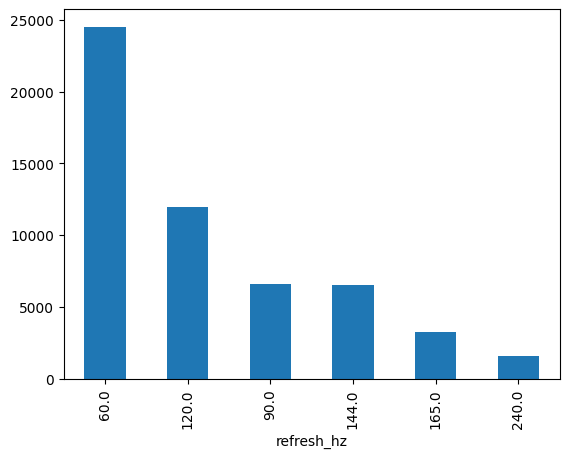

In [ ]:
df['refresh_hz'].value_counts().plot(kind='bar')

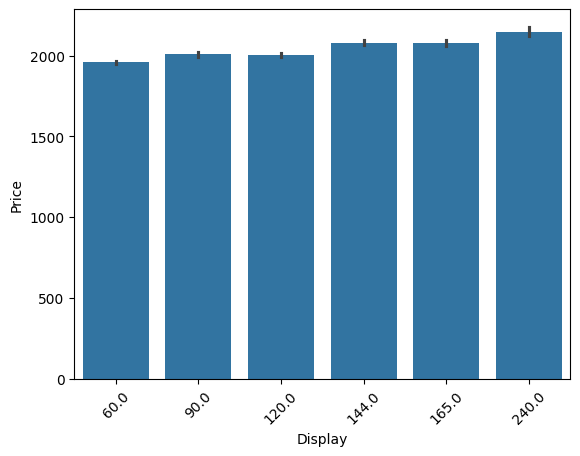

In [ ]:
sns.barplot(x=df['refresh_hz'],y=df['price'])
plt.xlabel('Display')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='battery_wh'>

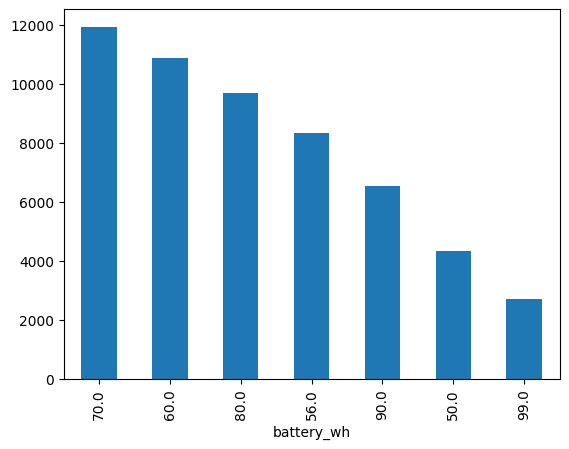

In [ ]:
df['battery_wh'].value_counts().plot(kind='bar')

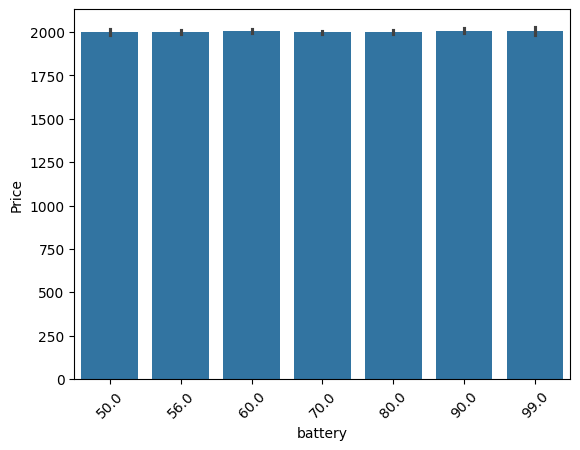

In [ ]:
sns.barplot(x=df['battery_wh'],y=df['price'])
plt.xlabel('battery')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='charger_watts'>

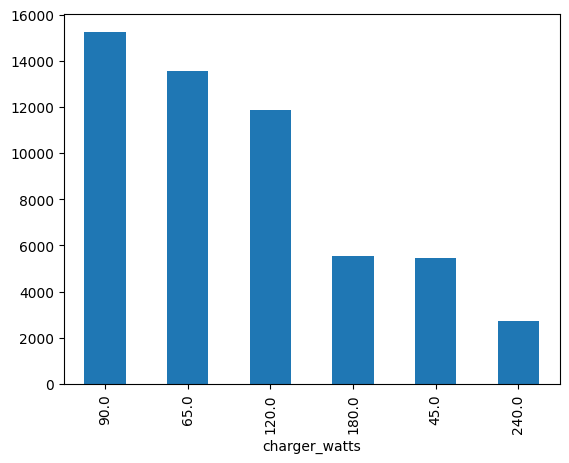

In [ ]:
df['charger_watts'].value_counts().plot(kind='bar')

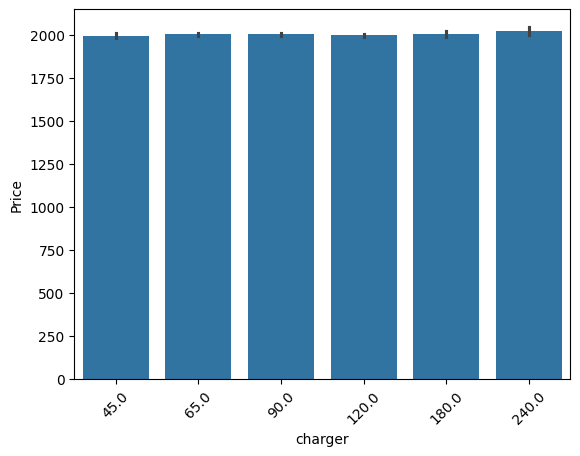

In [ ]:
sns.barplot(x=df['charger_watts'],y=df['price'])
plt.xlabel('charger')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='wifi'>

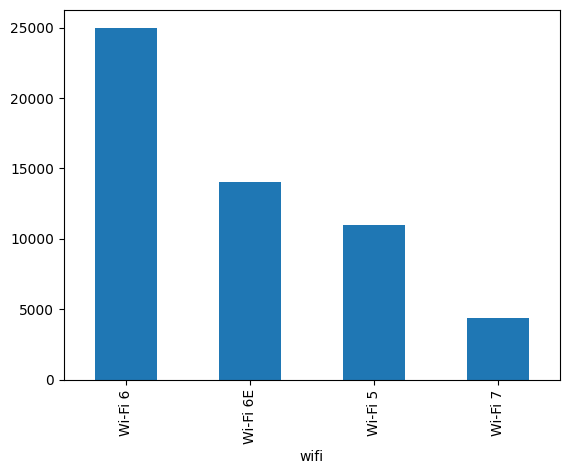

In [ ]:
df['wifi'].value_counts().plot(kind='bar')

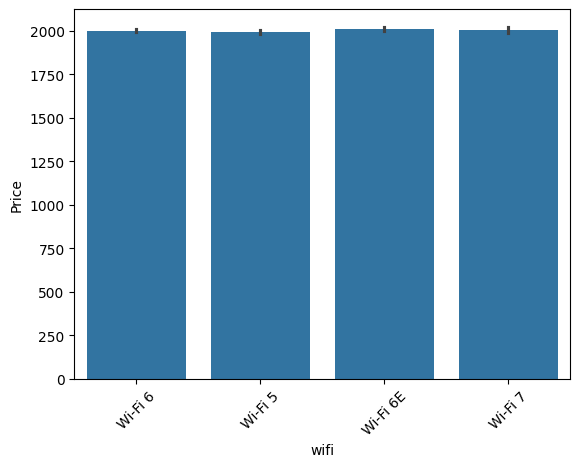

In [ ]:
sns.barplot(x=df['wifi'],y=df['price'])
plt.xlabel('wifi')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='bluetooth'>

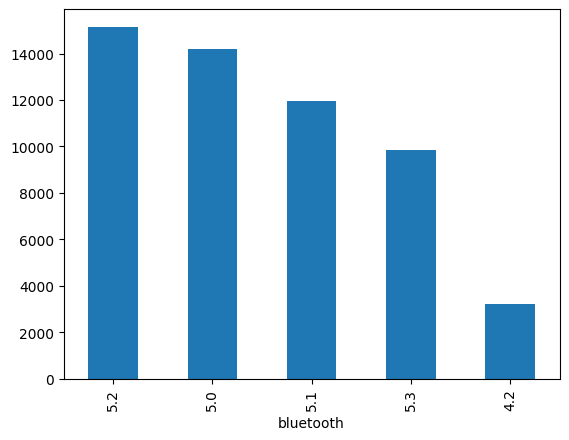

In [ ]:
df['bluetooth'].value_counts().plot(kind='bar')

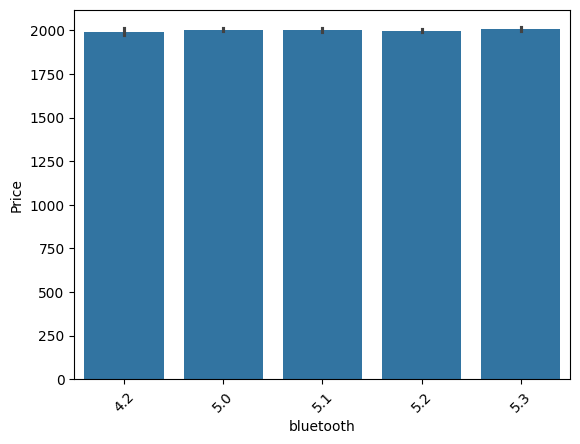

In [ ]:
sns.barplot(x=df['bluetooth'],y=df['price'])
plt.xlabel('bluetooth')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

In [ ]:
df['weight_kg'].value_counts()

,count
weight_kg,
1.50,5770
1.37,4864
1.70,4579
1.57,4005
1.30,3642
1.17,3089
2.00,2985
1.87,2430
1.53,1815


<Axes: xlabel='weight_kg'>

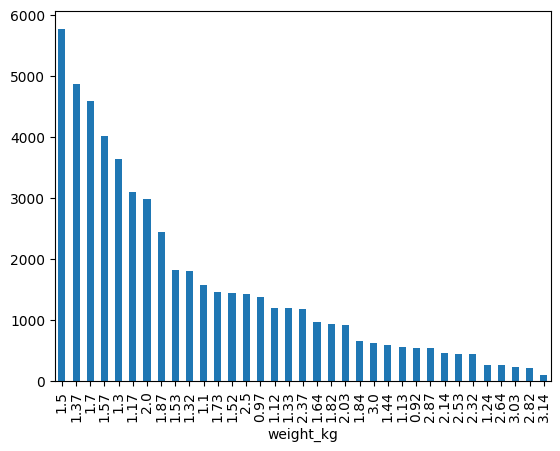

In [ ]:
df['weight_kg'].value_counts().plot(kind='bar')

/tmp/ipykernel_477/3885432485.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x=df['weight_kg'])


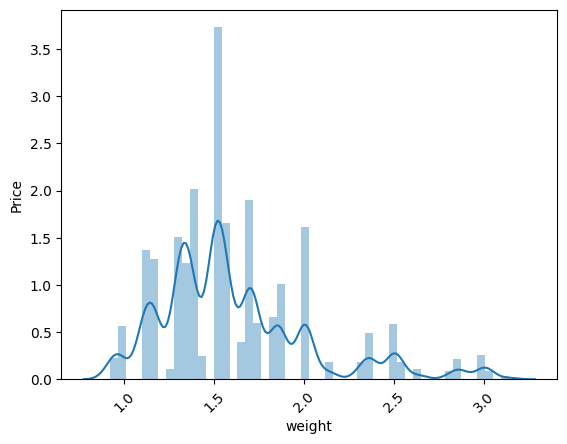

In [ ]:
sns.distplot(x=df['weight_kg'])
plt.xlabel('weight')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='warranty_months'>

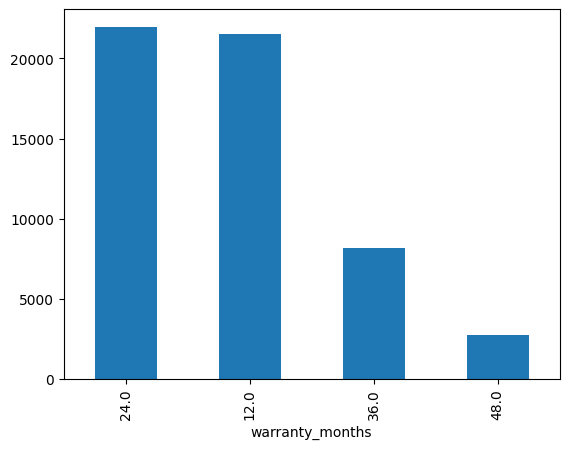

In [ ]:
df['warranty_months'].value_counts().plot(kind='bar')

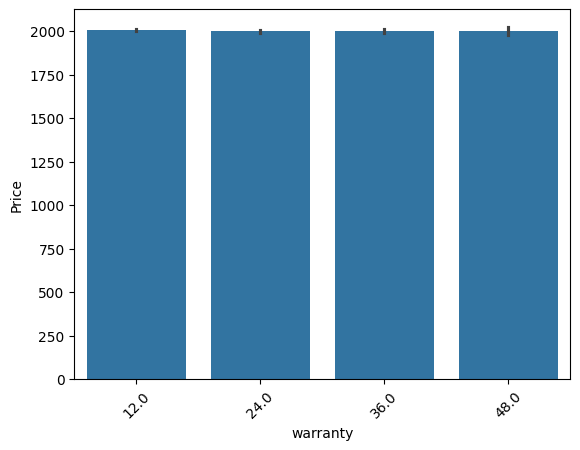

In [ ]:
sns.barplot(x=df['warranty_months'],y=df['price'])
plt.xlabel('warranty')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 54404 entries, 1 to 90944
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                54404 non-null  object 
 1   release_year         54404 non-null  int64  
 2   os                   54404 non-null  object 
 3   form_factor          54404 non-null  object 
 4   cpu_brand            54404 non-null  object 
 5   cpu_model            54404 non-null  object 
 6   cpu_tier             54404 non-null  int64  
 7   cpu_cores            54404 non-null  int64  
 8   cpu_threads          54404 non-null  int64  
 9   cpu_base_ghz         54404 non-null  float64
 10  gpu_brand            54404 non-null  object 
 11  gpu_model            54404 non-null  object 
 12  gpu_tier             54404 non-null  float64
 13  vram_gb              54404 non-null  float64
 14  ram_gb               54404 non-null  float64
 15  storage_type         54404 non-null  obje

In [ ]:
df.head()

,brand,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,cpu_cores,cpu_threads,cpu_base_ghz,...,refresh_hz,battery_wh,charger_watts,wifi,bluetooth,weight_kg,warranty_months,price,cpu_family,gpu_family
1,Samsung,2022,Windows,Mainstream,Intel,Intel i7-11114,4,12,24,2.6,...,90.0,56.0,120.0,Wi-Fi 6,5.3,2.03,12.0,2274.99,Intel i7,RTX 4080 series
4,Gigabyte,2024,Linux,Gaming,AMD,AMD Ryzen 7 6230,5,16,32,2.8,...,90.0,80.0,90.0,Wi-Fi 6,5.2,1.50,12.0,2681.99,AMD Ryzen 7,RTX 3080 series
8,Dell,2024,Windows,Mainstream,Intel,Intel i9-14473,6,26,52,3.0,...,60.0,80.0,240.0,Wi-Fi 5,5.0,1.17,48.0,2953.99,Intel i9,RTX 40 90
9,Lenovo,2025,Windows,Ultrabook,AMD,AMD Ryzen 3 4374,1,4,8,2.0,...,120.0,60.0,45.0,Wi-Fi 6,5.3,1.50,24.0,1653.99,AMD Ryzen 3,RTX 30 50
10,HP,2023,Windows,Mainstream,Intel,Intel i5-13209,2,6,12,2.2,...,165.0,70.0,90.0,Wi-Fi 6E,5.2,1.24,36.0,1371.99,Intel i5,RTX 40 60


In [ ]:
df['X_res']=df['resolution'].str.split('x').str.get(0).astype(float)


In [ ]:
df['Y_res']=df['resolution'].str.split('x').str.get(1).astype(float)

In [ ]:
df.head()

,brand,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,cpu_cores,cpu_threads,cpu_base_ghz,...,charger_watts,wifi,bluetooth,weight_kg,warranty_months,price,cpu_family,gpu_family,X_res,Y_res
1,Samsung,2022,Windows,Mainstream,Intel,Intel i7-11114,4,12,24,2.6,...,120.0,Wi-Fi 6,5.3,2.03,12.0,2274.99,Intel i7,RTX 4080 series,1920.0,1080.0
4,Gigabyte,2024,Linux,Gaming,AMD,AMD Ryzen 7 6230,5,16,32,2.8,...,90.0,Wi-Fi 6,5.2,1.50,12.0,2681.99,AMD Ryzen 7,RTX 3080 series,2560.0,1600.0
8,Dell,2024,Windows,Mainstream,Intel,Intel i9-14473,6,26,52,3.0,...,240.0,Wi-Fi 5,5.0,1.17,48.0,2953.99,Intel i9,RTX 40 90,2560.0,1600.0
9,Lenovo,2025,Windows,Ultrabook,AMD,AMD Ryzen 3 4374,1,4,8,2.0,...,45.0,Wi-Fi 6,5.3,1.50,24.0,1653.99,AMD Ryzen 3,RTX 30 50,3840.0,2160.0
10,HP,2023,Windows,Mainstream,Intel,Intel i5-13209,2,6,12,2.2,...,90.0,Wi-Fi 6E,5.2,1.24,36.0,1371.99,Intel i5,RTX 40 60,1920.0,1080.0


In [ ]:
df['ppi']=(((df['X_res']**2)+(df['Y_res']**2))**0.5)/df['display_size_in'].astype(float)

In [ ]:
df.head()

,brand,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,cpu_cores,cpu_threads,cpu_base_ghz,...,wifi,bluetooth,weight_kg,warranty_months,price,cpu_family,gpu_family,X_res,Y_res,ppi
1,Samsung,2022,Windows,Mainstream,Intel,Intel i7-11114,4,12,24,2.6,...,Wi-Fi 6,5.3,2.03,12.0,2274.99,Intel i7,RTX 4080 series,1920.0,1080.0,137.681698
4,Gigabyte,2024,Linux,Gaming,AMD,AMD Ryzen 7 6230,5,16,32,2.8,...,Wi-Fi 6,5.2,1.50,12.0,2681.99,AMD Ryzen 7,RTX 3080 series,2560.0,1600.0,193.517562
8,Dell,2024,Windows,Mainstream,Intel,Intel i9-14473,6,26,52,3.0,...,Wi-Fi 5,5.0,1.17,48.0,2953.99,Intel i9,RTX 40 90,2560.0,1600.0,215.633854
9,Lenovo,2025,Windows,Ultrabook,AMD,AMD Ryzen 3 4374,1,4,8,2.0,...,Wi-Fi 6,5.3,1.50,24.0,1653.99,AMD Ryzen 3,RTX 30 50,3840.0,2160.0,282.423996
10,HP,2023,Windows,Mainstream,Intel,Intel i5-13209,2,6,12,2.2,...,Wi-Fi 6E,5.2,1.24,36.0,1371.99,Intel i5,RTX 40 60,1920.0,1080.0,127.335675


In [ ]:
df.corr(numeric_only=True)['price']

,price
release_year,0.085264
cpu_tier,0.777681
cpu_cores,0.751566
cpu_threads,0.606041
cpu_base_ghz,0.777681
gpu_tier,0.804578
vram_gb,0.333275
ram_gb,0.792452
storage_gb,0.081680
storage_drive_count,0.000748


In [ ]:
df.columns

Index(['brand', 'release_year', 'os', 'form_factor', 'cpu_brand', 'cpu_model',
       'cpu_tier', 'cpu_cores', 'cpu_threads', 'cpu_base_ghz', 'gpu_brand',
       'gpu_model', 'gpu_tier', 'vram_gb', 'ram_gb', 'storage_type',
       'storage_gb', 'storage_drive_count', 'display_type', 'display_size_in',
       'resolution', 'refresh_hz', 'battery_wh', 'charger_watts', 'wifi',
       'bluetooth', 'weight_kg', 'warranty_months', 'price', 'cpu_family',
       'gpu_family', 'X_res', 'Y_res', 'ppi'],
      dtype='object')

In [ ]:
df.drop(columns=['X_res','Y_res','display_size_in','cpu_model','gpu_model'],inplace=True)

In [ ]:
df.columns

Index(['brand', 'release_year', 'os', 'form_factor', 'cpu_brand', 'cpu_tier',
       'cpu_cores', 'cpu_threads', 'cpu_base_ghz', 'gpu_brand', 'gpu_tier',
       'vram_gb', 'ram_gb', 'storage_type', 'storage_gb',
       'storage_drive_count', 'display_type', 'resolution', 'refresh_hz',
       'battery_wh', 'charger_watts', 'wifi', 'bluetooth', 'weight_kg',
       'warranty_months', 'price', 'cpu_family', 'gpu_family', 'ppi'],
      dtype='object')

In [ ]:
df.drop(columns=['cpu_tier','cpu_cores','cpu_threads','cpu_base_ghz','gpu_tier','resolution','battery_wh','charger_watts','wifi','bluetooth','warranty_months'],inplace=True)

In [ ]:
df.columns

Index(['brand', 'release_year', 'os', 'form_factor', 'cpu_brand', 'gpu_brand',
       'vram_gb', 'ram_gb', 'storage_type', 'storage_gb',
       'storage_drive_count', 'display_type', 'refresh_hz', 'weight_kg',
       'price', 'cpu_family', 'gpu_family', 'ppi'],
      dtype='object')

In [ ]:
df.head()

,brand,release_year,os,form_factor,cpu_brand,gpu_brand,vram_gb,ram_gb,storage_type,storage_gb,storage_drive_count,display_type,refresh_hz,weight_kg,price,cpu_family,gpu_family,ppi
1,Samsung,2022,Windows,Mainstream,Intel,NVIDIA,10.0,64.0,NVMe,512.0,1.0,OLED,90.0,2.03,2274.99,Intel i7,RTX 4080 series,137.681698
4,Gigabyte,2024,Linux,Gaming,AMD,NVIDIA,12.0,96.0,NVMe,256.0,1.0,Mini-LED,90.0,1.50,2681.99,AMD Ryzen 7,RTX 3080 series,193.517562
8,Dell,2024,Windows,Mainstream,Intel,NVIDIA,16.0,128.0,SSD,1024.0,1.0,LED,60.0,1.17,2953.99,Intel i9,RTX 40 90,215.633854
9,Lenovo,2025,Windows,Ultrabook,AMD,NVIDIA,4.0,8.0,NVMe,512.0,1.0,IPS,120.0,1.50,1653.99,AMD Ryzen 3,RTX 30 50,282.423996
10,HP,2023,Windows,Mainstream,Intel,NVIDIA,6.0,16.0,NVMe,1024.0,1.0,Mini-LED,165.0,1.24,1371.99,Intel i5,RTX 40 60,127.335675


In [ ]:
df.corr(numeric_only=True)['price']

,price
release_year,0.085264
vram_gb,0.333275
ram_gb,0.792452
storage_gb,0.081680
storage_drive_count,0.000748
refresh_hz,0.080919
weight_kg,0.000355
price,1.000000
ppi,0.177034


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score,mean_absolute_error


In [ ]:
from sklearn.pipeline import Pipeline

In [ ]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor
from xgboost import XGBRegressor


In [ ]:
df.head()

,brand,release_year,os,form_factor,cpu_brand,gpu_brand,vram_gb,ram_gb,storage_type,storage_gb,storage_drive_count,display_type,refresh_hz,weight_kg,price,cpu_family,gpu_family,ppi
1,Samsung,2022,Windows,Mainstream,Intel,NVIDIA,10.0,64.0,NVMe,512.0,1.0,OLED,90.0,2.03,2274.99,Intel i7,RTX 4080 series,137.681698
4,Gigabyte,2024,Linux,Gaming,AMD,NVIDIA,12.0,96.0,NVMe,256.0,1.0,Mini-LED,90.0,1.50,2681.99,AMD Ryzen 7,RTX 3080 series,193.517562
8,Dell,2024,Windows,Mainstream,Intel,NVIDIA,16.0,128.0,SSD,1024.0,1.0,LED,60.0,1.17,2953.99,Intel i9,RTX 40 90,215.633854
9,Lenovo,2025,Windows,Ultrabook,AMD,NVIDIA,4.0,8.0,NVMe,512.0,1.0,IPS,120.0,1.50,1653.99,AMD Ryzen 3,RTX 30 50,282.423996
10,HP,2023,Windows,Mainstream,Intel,NVIDIA,6.0,16.0,NVMe,1024.0,1.0,Mini-LED,165.0,1.24,1371.99,Intel i5,RTX 40 60,127.335675


In [ ]:
X=df.drop(columns=['price'])
Y=df['price']

In [ ]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [ ]:
import optuna
from sklearn.model_selection import cross_val_score

# **LINEAR REGRESSION**

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')


col2=LinearRegression()


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.8389252323974539
MAE 165.15082191117358


In [ ]:
# r2Score 0.8396239640398864
# MAE 169.17124459208188

# **KNN**

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')


col2=KNeighborsRegressor(n_neighbors=20)


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.6728376284644009
MAE 252.45014749262535


In [ ]:
# r2Score 0.7181131734871466
# MAE 233.47800150388503

# **SVM**

# **DECESIONTREE**

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')


col2=DecisionTreeRegressor(max_depth=9,random_state=42)


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.7746729209045886
MAE 202.93872373446314


In [ ]:
# r2Score 0.7838939344596207
# MAE 197.24975573091785

In [ ]:
df.shape

(13559, 18)

# **BAGGING REGRESSOR**

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')


col2=BaggingRegressor(random_state=42)


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.8150478801809167
MAE 182.0273598820059


In [ ]:
# r2Score 0.8120552329293838
# MAE 180.7747932158075

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
# classifier=GridSearchCV((pipe),{
#     'pipe2__n_estimators': [100,200,400,700],
#     'pipe2__max_samples': [0.25,0.1,0.5,0.15],
#     'pipe2__bootstrap': [True,False]
# },cv=3)
# classifier.fit(X,Y)
# best_model=classifier.cv_results_
# y_pred = best_model.predict(X_test)

# print('R2:', r2_score(Y_test, y_pred))
# print('MAE:', mean_absolute_error(Y_test, y_pred))

In [ ]:
def objective(trial):

    n_estimators = trial.suggest_int('n_estimators', 50, 500, step=50)
    max_samples = trial.suggest_float('max_samples', 0.1, 0.5)
    bootstrap = trial.suggest_categorical('bootstrap', [True, False])
    max_depth = trial.suggest_int('max_depth', 5, 30)

    model = BaggingRegressor(
        estimator=DecisionTreeRegressor(
            max_depth=max_depth,
            random_state=42
        ),
        n_estimators=n_estimators,
        max_samples=max_samples,
        bootstrap=bootstrap,
        random_state=42,
        n_jobs=-1
    )

    trial_pipe = Pipeline([
        ('pipe1', col1),
        ('pipe2', model)
    ])

    score = cross_val_score(
        trial_pipe,
        X_train,
        Y_train,
        cv=3,
        scoring='r2'
    ).mean()

    return score

In [ ]:
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=10,show_progress_bar=True)

print("Best Parameters:", study.best_params)
print("Best R2:", study.best_value)

In [ ]:
#Best Parameters: {'n_estimators': 350, 'max_samples': 0.16820964947491662, 'bootstrap': False, 'max_depth': 30}
#Best R2: 0.8245397408480591

# **RANDOM FOREST**

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')


col2=RandomForestRegressor(random_state=42)


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.8275546704773611
MAE 174.35594088003927


In [ ]:
# r2Score 0.8275546704773611
# MAE 174.35594088003927

In [ ]:
def objective(trial):

    n_estimators = trial.suggest_int('n_estimators', 50, 500, step=50)
    bootstrap = trial.suggest_categorical('bootstrap', [True, False])
    if bootstrap:
      max_samples = trial.suggest_float(
        'max_samples', 0.3, 1.0)
    else:
      max_samples = None
    max_depth = trial.suggest_int('max_depth', 10, 40)
    max_features = trial.suggest_categorical('max_features', [0.5, 0.75, 1.0])


    model = RandomForestRegressor(

        n_estimators=n_estimators,

        bootstrap=bootstrap,
        max_samples=max_samples,
        max_depth=max_depth,
        max_features=max_features,
        random_state=42,
        n_jobs=-1
    )

    trial_pipe = Pipeline([
        ('pipe1', col1),
        ('pipe2', model)
    ])

    score = cross_val_score(
        trial_pipe,
        X_train,
        Y_train,
        cv=3,
        scoring='r2'
    ).mean()

    return score

In [ ]:
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=50, show_progress_bar=True)

print("Best Parameters:", study.best_params)
print("Best R2:", study.best_value)

In [ ]:
#best params
#{'n_estimators': 450, 'bootstrap': True, 'max_samples': 0.6054691898586331, 'max_depth': 26, 'max_features': 0.5}.Best is trial 17 with value: 0.8414759867505864

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')


col2=RandomForestRegressor(n_estimators= 450, bootstrap= True, max_samples= 0.6054691898586331, max_depth= 26, max_features= 0.5,random_state=42)


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.8412185008345504
MAE 166.72948695137285


# **ADABOOST**

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')


col2=AdaBoostRegressor(random_state=42)


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.3688289591576731
MAE 389.42669475522337


In [ ]:
# r2Score 0.3688289591576731
# MAE 389.42669475522337

In [ ]:
def objective(trial):

    n_estimators = trial.suggest_int('n_estimators', 50, 500, step=50)
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-1, log=True)

    model = AdaBoostRegressor(

        n_estimators=n_estimators,
        learning_rate=learning_rate,

        random_state=42,

    )

    trial_pipe = Pipeline([
        ('pipe1', col1),
        ('pipe2', model)
    ])

    score = cross_val_score(
        trial_pipe,
        X_train,
        Y_train,
        cv=3,
        scoring='r2'
    ).mean()

    return score

In [ ]:
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=20, show_progress_bar=True)

print("Best Parameters:", study.best_params)
print("Best R2:", study.best_value)

[I 2026-11-05 23:08:40,645] A new study created in memory with name: no-name-0936d081-d97a-46c1-a57a-b599ba459b84


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-11-05 23:08:50,948] Trial 0 finished with value: 0.6902042223152495 and parameters: {'n_estimators': 200, 'learning_rate': 0.07114476009343425}. Best is trial 0 with value: 0.6902042223152495.
[I 2026-11-05 23:09:15,235] Trial 1 finished with value: 0.6927032299846783 and parameters: {'n_estimators': 400, 'learning_rate': 0.006251373574521752}. Best is trial 1 with value: 0.6927032299846783.
[I 2026-11-05 23:09:23,361] Trial 2 finished with value: 0.6932881708721842 and parameters: {'n_estimators': 100, 'learning_rate': 0.00029375384576328325}. Best is trial 2 with value: 0.6932881708721842.
[I 2026-11-05 23:09:26,093] Trial 3 finished with value: 0.6936773319891536 and parameters: {'n_estimators': 50, 'learning_rate': 0.0396760507705299}. Best is trial 3 with value: 0.6936773319891536.
[I 2026-11-05 23:09:46,081] Trial 4 finished with value: 0.6942374033056651 and parameters: {'n_estimators': 350, 'learning_rate': 0.013311216080736894}. Best is trial 4 with value: 0.6942374033

In [ ]:
# Best Parameters: {'n_estimators': 200, 'learning_rate': 0.0037520558551242854}
# Best R2: 0.6944965528710632

# **Gradient Boosting**

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')


col2=GradientBoostingRegressor(random_state=42)


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.8446667959985423
MAE 166.2290131856776


In [ ]:
# r2Score 0.8446667959985423
# MAE 166.2290131856776

In [ ]:

col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')


col2=GradientBoostingRegressor(n_estimators=500, learning_rate= 0.088939979040901, max_depth= 2, min_samples_split= 14, min_samples_leaf= 2,random_state=42)


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.8585812285834918
MAE 156.43893300528129


In [ ]:
def objective(trial):

    n_estimators = trial.suggest_int('n_estimators', 50, 500, step=50)
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-1, log=True)
    max_depth=trial.suggest_int('max_depth',2,8,step=2)
    min_samples_split=trial.suggest_int('min_samples_split',2,20,step=2)
    min_samples_leaf=trial.suggest_int('min_samples_leaf',2,10,step=2)


    model = GradientBoostingRegressor(

        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,



        random_state=42,

    )

    trial_pipe = Pipeline([
        ('pipe1', col1),
        ('pipe2', model)
    ])

    score = cross_val_score(
        trial_pipe,
        X_train,
        Y_train,
        cv=3,
        scoring='r2',
        n_jobs=-1
    ).mean()

    return score

In [ ]:
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=50, show_progress_bar=True)

print("Best Parameters:", study.best_params)
print("Best R2:", study.best_value)

In [ ]:
#best R2: 0.8708553161802738  best Parameters: {'n_estimators': 500, 'learning_rate': 0.088939979040901, 'max_depth': 2, 'min_samples_split': 14, 'min_samples_leaf': 2}

# **XGBOOST**

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')


col2=XGBRegressor(random_state=42)


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.8537607223052119
MAE 156.90870820012245


In [ ]:
def objective(trial):

    n_estimators = trial.suggest_int('n_estimators', 50, 600, step=50)
    learning_rate = trial.suggest_float('learning_rate', 0.01, 0.2, log=True)
    max_depth=trial.suggest_int('max_depth',3,10,step=1)



    model = XGBRegressor(

        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=max_depth,



        random_state=42,

    )

    trial_pipe = Pipeline([
        ('pipe1', col1),
        ('pipe2', model)
    ])

    score = cross_val_score(
        trial_pipe,
        X_train,
        Y_train,
        cv=3,
        scoring='r2',
        n_jobs=1
    ).mean()

    return score

In [ ]:
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=50, show_progress_bar=True)

print("Best Parameters:", study.best_params)
print("Best R2:", study.best_value)

[I 2026-11-07 23:26:52,280] A new study created in memory with name: no-name-4a6e6590-401e-4861-8fe8-ea0674ee6a33


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-11-07 23:27:02,568] Trial 0 finished with value: 0.8268928109188408 and parameters: {'n_estimators': 250, 'learning_rate': 0.17254716573280354, 'max_depth': 8}. Best is trial 0 with value: 0.8268928109188408.
[I 2026-11-07 23:27:16,277] Trial 1 finished with value: 0.8250268689723178 and parameters: {'n_estimators': 400, 'learning_rate': 0.015958237752949748, 'max_depth': 4}. Best is trial 0 with value: 0.8268928109188408.
[I 2026-11-07 23:27:24,856] Trial 2 finished with value: 0.8373531843053854 and parameters: {'n_estimators': 50, 'learning_rate': 0.13394334706750485, 'max_depth': 7}. Best is trial 2 with value: 0.8373531843053854.
[I 2026-11-07 23:28:14,134] Trial 3 finished with value: 0.8300308321644447 and parameters: {'n_estimators': 450, 'learning_rate': 0.010636066512540286, 'max_depth': 10}. Best is trial 2 with value: 0.8373531843053854.
[I 2026-11-07 23:28:27,387] Trial 4 finished with value: 0.8363574263483229 and parameters: {'n_estimators': 500, 'learning_rate':

In [ ]:
categorical_cols = [
    'brand', 'os', 'form_factor', 'cpu_brand',
    'gpu_brand', 'storage_type', 'display_type',
    'cpu_family', 'gpu_family'
]

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(
        sparse_output=False,
        drop='first',
        handle_unknown='ignore'
    ), categorical_cols)
], remainder='passthrough')


models = {
    'Gradient Boosting Tuned': GradientBoostingRegressor(
        n_estimators=500,
        learning_rate=0.088939979,
        max_depth=2,
        min_samples_split=14,
        min_samples_leaf=2,
        random_state=42
    ),

    'XGBoost Default': XGBRegressor(
        random_state=42,
        n_jobs=-1
    ),

    'XGBoost Tuned': XGBRegressor(
        n_estimators=500,
        learning_rate=0.120399818,
        max_depth=3,
        random_state=42,
        n_jobs=-1
    )
}


for name, model in models.items():

    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipe.fit(X_train, Y_train)
    pred = pipe.predict(X_test)

    print(name)
    print('R2:', r2_score(Y_test, pred))
    print('MAE:', mean_absolute_error(Y_test, pred))
    print('-' * 40)

Gradient Boosting Tuned
R2: 0.8585812285827654
MAE: 156.43893300554754
----------------------------------------
XGBoost Default
R2: 0.8537607223052119
MAE: 156.90870820012245
----------------------------------------
XGBoost Tuned
R2: 0.8648427644154874
MAE: 150.8468052819311
----------------------------------------


# **Residual analysis**

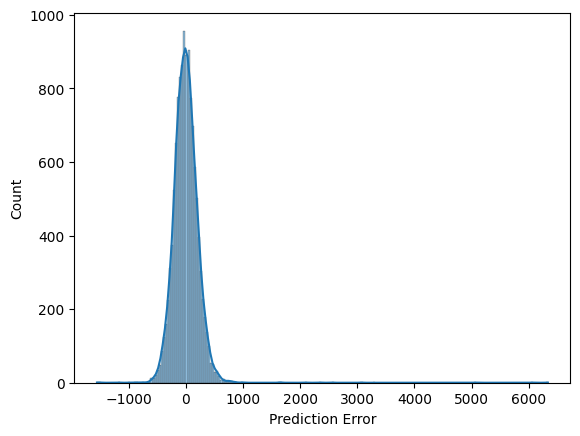

In [ ]:
residuals = Y_test - y_pred

sns.histplot(residuals, kde=True)
plt.xlabel('Prediction Error')
plt.show()

# **VOTING REGRESSOR**

In [ ]:
from sklearn.ensemble import VotingRegressor
from sklearn.ensemble import StackingRegressor

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')

lr=LinearRegression()
xgb=XGBRegressor(n_estimators=500,learning_rate=0.120399818,max_depth=3,random_state=42,n_jobs=-1)
rf=RandomForestRegressor(n_estimators= 450, bootstrap= True, max_samples= 0.6054691898586331, max_depth= 26, max_features= 0.5,random_state=42)
gb=GradientBoostingRegressor(n_estimators=500,learning_rate=0.088939979,max_depth=2,min_samples_split=14,min_samples_leaf=2,random_state=42)
col2=VotingRegressor([('rf',rf),('gb',gb),('xgb',xgb)],weights=[1,2,3])


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.8627909632515172
MAE 152.72255637772577


# **Stacking**

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')

lr=LinearRegression()
xgb=XGBRegressor(n_estimators=500,learning_rate=0.120399818,max_depth=3,random_state=42,n_jobs=-1)
rf=RandomForestRegressor(n_estimators= 450, bootstrap= True, max_samples= 0.6054691898586331, max_depth= 26, max_features= 0.5,random_state=42)
gb=GradientBoostingRegressor(n_estimators=500,learning_rate=0.088939979,max_depth=2,min_samples_split=14,min_samples_leaf=2,random_state=42)
col2=StackingRegressor([('rf',rf),('gb',gb),('xgb',xgb)])


pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



pipe.fit(X_train,Y_train)
y_pred=pipe.predict(X_test)

print('r2Score',r2_score(Y_test,y_pred))
print('MAE',mean_absolute_error(Y_test,y_pred))

r2Score 0.8648628709453039
MAE 150.85204572037787


# **FINAL XGB**

In [ ]:
col1=ColumnTransformer([
    ('OneHotEncoder',OneHotEncoder(sparse_output=False,drop='first'),[0,2,3,4,5,8,11,14,15])
],remainder='passthrough')


col2=XGBRegressor(n_estimators=500,
        learning_rate=0.120399818,
        max_depth=3,
        random_state=42,
        n_jobs=-1)


final_pipe=Pipeline([
    ('pipe1',col1),
    ('pipe2',col2)
])



final_pipe.fit(X,Y)


Pipeline(steps=[('pipe1',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('OneHotEncoder',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  [0, 2, 3, 4, 5, 8, 11, 14,
                                                   15])])),
                ('pipe2',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_bytree=None, device=None,
                              early_stopping_rounds=None,
                              enabl...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None,
                              learning_rate=0.120399818, max_bin=None,
                              max_cat_threshold=None, max_cat_to_onehot=None,
                              max_delta_step=None, max_depth=3, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=500, n_jobs=-1,
                              num_parallel_tree=None, ...))])

EXPORTING

In [ ]:
import joblib
joblib.dump(df, 'df.joblib')

In [ ]:
loaded_model = joblib.load('laptop_price_model.joblib')

y_pred = loaded_model.predict(X_test)

print(y_pred[:10])

[2616.4636 1077.8446 1818.71   1403.3984 1790.386  1568.6287 1309.2094
 2045.8882 2030.3826 2120.1626]


In [ ]:
df

,brand,release_year,os,form_factor,cpu_brand,gpu_brand,vram_gb,ram_gb,storage_type,storage_gb,storage_drive_count,display_type,refresh_hz,weight_kg,price,cpu_family,gpu_family,ppi
1,Samsung,2022,Windows,Mainstream,Intel,NVIDIA,10,64,NVMe,512,1,OLED,90,2.03,2274.99,Intel i7,RTX 4080 series,137.681698
4,Gigabyte,2024,Linux,Gaming,AMD,NVIDIA,12,96,NVMe,256,1,Mini-LED,90,1.50,2681.99,AMD Ryzen 7,RTX 3080 series,193.517562
8,Dell,2024,Windows,Mainstream,Intel,NVIDIA,16,128,SSD,1024,1,LED,60,1.17,2953.99,Intel i9,RTX 40 90,215.633854
9,Lenovo,2025,Windows,Ultrabook,AMD,NVIDIA,4,8,NVMe,512,1,IPS,120,1.50,1653.99,AMD Ryzen 3,RTX 30 50,282.423996
10,HP,2023,Windows,Mainstream,Intel,NVIDIA,6,16,NVMe,1024,1,Mini-LED,165,1.24,1371.99,Intel i5,RTX 40 60,127.335675
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99993,Acer,2022,Windows,Gaming,AMD,AMD,8,32,NVMe,512,1,Mini-LED,60,1.70,1658.99,AMD Ryzen 5,RX 7000 series,141.211998
99995,ASUS,2023,Windows,Mainstream,Intel,AMD,8,32,HDD,2048,1,LED,144,1.87,1712.99,Intel i7,RX 7000 series,157.350512
99996,Lenovo,2018,Windows,Ultrabook,AMD,AMD,4,8,HDD,1024,1,LED,90,1.37,1258.99,AMD Ryzen 5,RX 6000 series,215.633854
99997,ASUS,2020,Windows,Mainstream,Intel,NVIDIA,6,16,NVMe,1024,1,OLED,120,1.17,1686.99,Intel i5,RTX 20 60,215.633854


In [ ]:
print(final_pipe.named_steps)

{'pipe1': ColumnTransformer(remainder='passthrough',
                  transformers=[('OneHotEncoder',
                                 OneHotEncoder(drop='first',
                                               sparse_output=False),
                                 [0, 2, 3, 4, 5, 8, 11, 14, 15])]), 'pipe2': XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.120399818, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimator

In [ ]:
import joblib


joblib.dump(
    final_pipe.named_steps['pipe1'],
    'laptop_preprocessor.joblib'
)


final_pipe.named_steps['pipe2'].save_model('xgb_model.json')

In [ ]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

col1 = ColumnTransformer([
    ('OneHotEncoder',
     OneHotEncoder(sparse_output=False, drop='first'),
     [0, 2, 3, 4, 5, 8, 11, 14, 15])
], remainder='passthrough')

models = {

    'XGBoost Tuned': XGBRegressor(
        n_estimators=500,
        learning_rate=0.120399818,
        max_depth=3,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting Tuned': GradientBoostingRegressor(
        n_estimators=500,
        learning_rate=0.088939979,
        max_depth=2,
        min_samples_split=14,
        min_samples_leaf=2,
        random_state=42
    )

}

for name, model in models.items():

    # ORIGINAL TARGET PIPELINE

    original_pipe = Pipeline([
        ('pipe1', clone(col1)),
        ('pipe2', clone(model))
    ])

    original_pipe.fit(X_train, Y_train)

    pred_original = original_pipe.predict(X_test)


    # LOG TRANSFORMED TARGET PIPELINE

    log_pipe = TransformedTargetRegressor(

        regressor=Pipeline([
            ('pipe1', clone(col1)),
            ('pipe2', clone(model))
        ]),

        func=np.log,
        inverse_func=np.exp
    )

    log_pipe.fit(X_train, Y_train)

    pred_log = log_pipe.predict(X_test)


    # COMPARISON

    print('\n', '=' * 45)
    print(name)
    print('=' * 45)

    print('\nOriginal Target')

    print('R2:', r2_score(Y_test, pred_original))

    print('MAE:', mean_absolute_error(Y_test, pred_original))


    print('\nLog Transformed Target')

    print('R2:', r2_score(Y_test, pred_log))

    print('MAE:', mean_absolute_error(Y_test, pred_log))

    print('-' * 45)


XGBoost Tuned

Original Target
R2: 0.8445201285132587
MAE: 152.09022339506652

Log Transformed Target
R2: 0.8443538158625813
MAE: 152.10045446190605
---------------------------------------------

Gradient Boosting Tuned

Original Target
R2: 0.838415102702327
MAE: 157.01830070410426

Log Transformed Target
R2: 0.8369817187325665
MAE: 158.2775929822302
---------------------------------------------
